# Coparing cDC1 vs cDC2 derived mregDC signatures (Cheng 2021) and further investigating mregDC heterogeneity

In [1]:
#load packages I need
import os
import tools
import scanpy as sc
import pandas as pd
import dandelion as ddl
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

/home/s4436039/miniforge3/envs/envpy26/lib/python3.10/site-packages/nxviz/__init__.py:33: UserWarning: 
nxviz has a new API! Version 0.7.4 onwards, the old class-based API is being
deprecated in favour of a new API focused on advancing a grammar of network
graphics. If your plotting code depends on the old API, please consider
pinning nxviz at version 0.7.4, as the new API will break your old code.

To check out the new API, please head over to the docs at
https://ericmjl.github.io/nxviz/ to learn more. We hope you enjoy using it!

(This deprecation message will go away in version 1.0.)



In [2]:
#set current directory 
os.chdir('/scratch/user/s4436039/scdata/Myeloid_Objects')
os.getcwd()

'/scratch/user/s4436039/scdata/Myeloid_Objects'

In [3]:
# read in data
data = sc.read_h5ad('20250617_AllDC_bbknn.h5ad')

In [4]:
data

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions'

In [5]:
sc.set_figure_params(dpi=100, dpi_save=700, vector_friendly=True, format='svg') #only run when exporting umaps

In [6]:
print(data.uns["NR_annotations_simple_colors"])

['#c53a32' '#9e47f3' '#84594f']


In [7]:
# Set colours for NR_annotations_simple plot:
data.uns["NR_annotations_simple_colors"] = ['#e377c2', '#aa40fc', '#8c564b']  

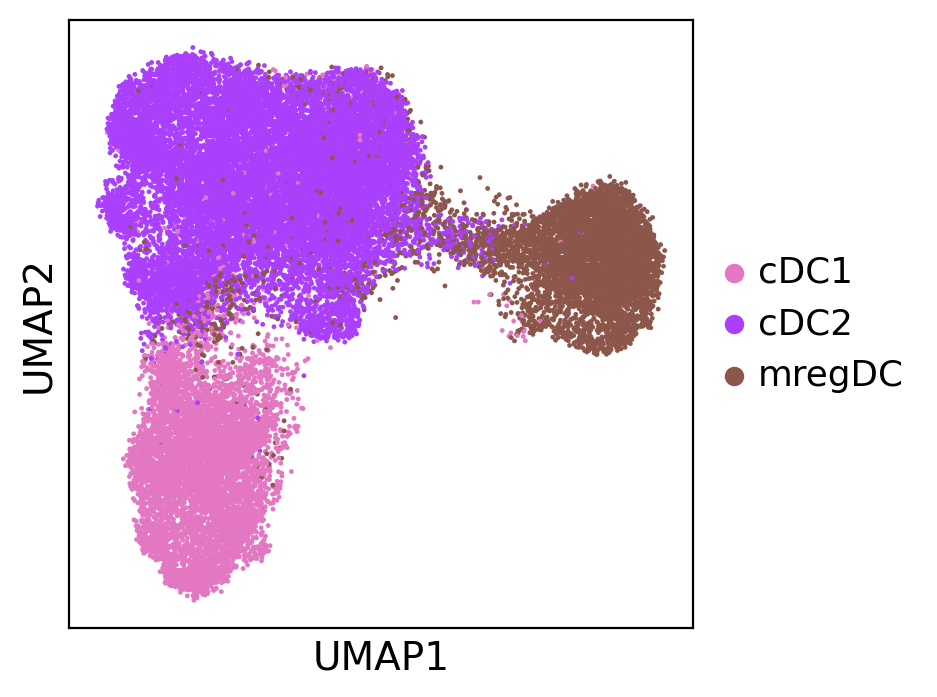

In [8]:
#export high res umap
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data, 
               color="NR_annotations_simple", 
               size=12,
               title="")

In [12]:
#cDC1 derived mregDC vs cDC2 derived mregDC from Cheng
#Cheng et al 2021 Table S3, logFC>0 for cDC1-mregDC sig, logFC<0 for cDC2-mregDC sig
cDC1_mregDC = ['GPR153','SLC2A5','GPR157','PRDM2','PADI2','ECE1','TMEM57','MARCKSL1','MACF1','CDKN2C','TACSTD2','ROR1','IL23R','GADD45A','MCOLN2','RHOC','PPM1J','MAGI3','ATP1A1','FAM46C','ACP6','C1orf54','ENSA','S100A10','DCAF6','RABGAP1L','C1orf21','FAM129A','RGS1','RGS13','TNNT2','LAD1','NAV1','RAB7B','BATF3','CDC42BPA','C1orf198','KIF26B','LINC00298','ID2','GEN1','RAB10','RASGRP3','MAP4K3','MTA3','FOXN2','RTN4','PELI1','LGALSL','AFTPH','PCBP1','TEX261','NEURL3','TBC1D8','MAP4K4','BCL2L11','FOXD4L1','CYTIP','LY75','TANK','TTN-AS1','TTN','ITGA4','PPP1R1C','NABP1','RAPH1','AC079767.4','PIKFYVE','IKZF2','SP140','ATG16L1','RAMP1','FARP2','ING5','IRAK2','THRB','LRRFIP2','PLCD1','OXSR1','RP11-761N21.1','LZTFL1','FLNB','DNASE1L3','LRIG1','FOXP1','ROBO1','CBLB','GCSAM','CD200','BTLA','POGLUT1','PLXNA1','MGLL','SLC9A9','RAP2B','MAP3K13','LPP','CLNK','ARAP2','KLF3','LIMCH1','KIAA1211','RUFY3','GRSF1','MOB1B','G3BP2','PPM1K','TIGD2','DAPP1','H2AFZ','NOCT','IL15','INPP4B','SMARCA5','ZNF827','CASP3','CTD-2231H16.1','CCDC127','OTULIN','ANKRD55','GPBP1','KIF2A','ST8SIA4','CAMK4','EPB41L4A','SEMA6A','SLC12A2','FSTL4','ANXA6','SLC36A1','G3BP1','CYFIP2','RP11-524N5.1','IL12B','DUSP1','ERGIC1','ATP6V0E1','MGAT4B','SQSTM1','SERPINB9','TUBB2A','BTN2A2','HIST1H2BK','HLA-F','HLA-G','HLA-A','HLA-E','HLA-C','HLA-B','HLA-DOB','BRD2','DST','FAM135A','HMGN3','ZUFSP','NCOA7','PTPRK','EYA4','PPP1R14C','PLEKHG1','ZBTB2','TIAM2','GPR31','CCZ1','EIF2AK1','TSPAN13','CCDC126','H2AFV','LANCL2','VOPP1','TPST1','AUTS2','TFPI2','GNG11','COL1A2','MUC12','CDHR3','DNAJB9','TES','CAV1','ST7','TMSB4X','RAB9A','MOSPD2','ACOT9','DMD','CHST7','SLC9A7','PAGE2','KLF8','P2RY10','ZCCHC18','NXT2','WDR44','CXorf40A','CLIC2','FBXO25','SGK223','PNOC','DUSP4','RAB11FIP1','IDO1','NSMAF','TOX','RP11-25K19.1','HEY1','CPNE3','PABPC1','TRIB1','ST3GAL1','PTK2','ZNF250','FOXD4','ANKRD20A2','FAM95B1','ANKRD20A4','FOXD4L4','ANKRD20A3','ANKRD20A1','FOXD4L3','TJP2','NMRK1','OSTF1','RFK','GCNT1','CKS2','SEC61B','TXN','FNBP1','CLIC3','FUT7','GRIN1','ANO9','LSP1','RPL27A','RNF141','LYVE1','LDLRAD3','MDK','PLA2G16','NRXN2','MALAT1','KLC2','GSTP1','GDPD5','BIRC3','TMEM123','CADM1','TMEM136','NET1','UPF2','DHTKD1','OPTN','FRMD4A','ZEB1','MAPK8','WDFY4','CCDC6','JMJD1C-AS1','REEP3','H2AFY2','AIFM2','VDAC2','ENTPD7','ERLIN1','DUSP5','SHTN1','RP11-598F7.3','WNK1','CLEC2D','PRR4','BCL2L14','ATF7IP','OVOS2','RND1','TUBA1C','SPATS2','RAB5B','MYL6','DYRK2','NAP1L1','PAWR','NAA25','RAB35','USP12','RPL21','FLT3','ENOX1','LACC1','KIAA0226L','TBC1D4','MBNL2','EFNB2','ARHGAP5','NIN','DAAM1','DNAL1','PNMA1','SLC24A4','SLC25A29','CKB','IGHV6-1','MTMR10','B2M','MYEF2','FBN1','GABPB1','RPS27L','RAB8B','RPLP1','ARNT2','WHAMM','FAM174B','PDPK1','TXNDC11','ZC3H7A','ARHGAP17','NLRC5','WWP2','VAC14','ZNRF1','GABARAPL2','IRF8','VMO1','PFN1','ENO3','UBB','RAB11FIP4','C17orf96','CCR7','EIF1','RAMP2','CTD-2020K17.1','ERN1','ABCA5','TTYH2','HN1','C17orf99','CYTH1','ACTG1','TUBB6','MEX3C','TXNL1','MALT1','PMAIP1','TNFRSF11A','TSHZ1','ACSS2','TOMM34','STK4','EYA2','ZFAS1','RPS21','KISS1R','IZUMO4','AC024592.12','RPS28','CTC-548K16.1','HSH2D','CIB3','KCNN1','TBCB','SIPA1L3','FBXO17','FBXO27','CLASRP','ZNF296','HSD17B14','BID','ZNF280B','ADORA2A','APOBEC3B','ATF4','ENTHD1','GRAP2','RANGAP1','BIK','NRIP1','AJ006998.2','CYYR1','SOD1','TMEM50B','FAM3B','C2CD2']
cDC2_mregDC = ['TNFRSF14','KCNAB2','ENO1','PGD','AGTRAP','TMEM51','EFHD2','NECAP2','MINOS1','C1QA','C1QC','C1QB','SH3BGRL3','FGR','IFI6','THEMIS2','PTAFR','LAPTM5','AK2','ZMYM6NB','LSM10','CSF3R','UTP11L','ATP6V0B','PLK3','AKR1A1','SCP2','MAGOH','GBP1','GBP2','GBP4','GBP5','RPL5','DPYD','CD53','DRAM2','C1orf162','RAP1A','TXNIP','S100A11','S100A9','S100A6','S100A4','S100A13','LAMTOR2','LMNA','GLMP','CD1D','RP11-404O13.5','CD1A','CD1C','CD1B','CD1E','MNDA','IFI16','FCER1A','DUSP23','SLAMF8','IGSF8','PEA15','SLAMF1','FCER1G','FCGR2A','FCGR2B','RCSD1','ABL2','QSOX1','GLUL','RGS16','NCF2','PTPRC','RASSF5','IARS2','GUK1','NLRP3','CMPK2','LAPTM4A','TP53I3','SNX17','RBKS','PPP1CB','WDR43','EIF2AK2','GALM','SLC8A1','EML4','ZFP36L2','PNPT1','ACTR2','ARHGAP25','CLEC4F','CD207','DGUOK','HTRA2','DOK1','POLE4','CAPG','VAMP8','LINC00152','IGKV1-17','IGKV3-20','MRPS5','COX5B','IL1R2','LIMS1','IL1B','IL1RN','DBI','HNMT','KYNU','ZEB2','CD302','WIPF1','ATP5G3','ITGAV','STAT1','ANKRD44','FTCDNL1','ACSL3','SP140L','SP100','NCL','INPP5D','ARL4C','SH3BP5','CCRL2','GPX1','GNAI2','MAPKAPK3','ACY1','TWF2','TKT','MITF','FILIP1L','NDUFB4','HCLS1','CSTA','PLXND1','MRPL3','DNAJC13','RNF7','PLSCR1','HPS3','SERP1','EIF2A','P2RY13','SSR3','MFSD1','TNFSF10','NDUFB5','MCCC1','B3GNT5','AP2M1','CCDC50','ATP13A3','C4orf48','LRPAP1','LAP3','RBM47','OCIAD1','CXCL8','CXCL3','CXCL2','EREG','CXCL11','SCARB2','ANXA3','RASGEF1B','GPAT3','HSD17B11','PYURF','GPRIN3','AF213884.2','C4orf3','ANXA5','MGST2','MAML3','TLR2','FAM105A','SLC1A3','FYB','CCNH','MCTP1','GLRX','CAST','ERAP2','REEP5','SNX2','UQCRQ','H2AFY','TGFBI','TMEM173','HBEGF','SRA1','EIF4EBP3','CD14','CSF1R','SMIM3','LCP2','SH3PXD2B','CLTB','PRELID1','RNF130','NEDD9','UBD','IER3','LST1','AIF1','CLIC1','GPSM3','HLA-DQB1','HLA-DQA2','PSMB9','HLA-DMB','HLA-DMA','NUDT3','DEF6','FKBP5','TREM2','TREM1','CNPY3','VEGFA','NFKBIE','PLA2G7','CD109','SLC16A10','FAM26F','ARHGAP18','DYNLT1','SYTL3','TAGAP','SOD2','RNASET2','C7orf50','NUDT1','SNX8','MACC1','NFE2L3','SNX10','AOAH','INHBA','MRPS24','TNS3','FGL2','ARPC1B','ATP5J2','PILRA','FIS1','RASA4','RP11-325F22.2','SYPL1','DOCK4','CAPZA2','TBXAS1','GSTK1','TPK1','GIMAP4','TMEM176B','TMEM176A','PRKAG2-AS1','IL3RA','CD99','CYBB','ATP6AP2','CFP','WAS','LINC01420','VSIG4','COX7B','SH3BGRL','BTK','SLC25A5','FAM58A','BCAP31','IDH3G','ATP6AP1','CTSB','MSR1','ASAH1','ATP6V1B2','DOK2','MRPL15','TMEM70','LY96','DECR1','KLF10','ENY2','SLA','LY6E','GRINA','PDCD1LG2','TMEM261','PLIN2','HACD4','B4GALT1','FAM122A','ANXA1','FBP1','ABCA1','GNG10','SLC31A1','CDC26','ATP6V1G1','ENG','CARD9','TOR4A','IFITM2','IFITM1','IFITM3','CD81','PHLDA2','TRIM22','IPO7','C11orf58','NUCB2','LDHA','CAT','CD44','SPI1','SLC43A3','UBE2L6','C11orf31','CTNND1','LPXN','MS4A6A','MS4A4A','MS4A7','FTH1','RARRES3','BANF1','UNC93B1','NDUFS8','TCIRG1','ARRB1','PICALM','CTSC','SMCO4','TRPC6','CASP4','CASP1','CARD16','IL18','JAML','SORL1','ROBO3','DCPS','ST14','VPS26B','GDI2','ATP5C1','CDC123','CAMK1D','MRC1','PLXDC2','APBB1IP','ALOX5','FAM21C','NCOA4','PCBD1','PSAP','DDIT4','C10orf11','KCNMA1','ANXA11','GLUD1','ANKRD22','MYOF','ENTPD1','PIK3AP1','SFR1','GSTO1','CD9','GAPDH','CD4','TPI1','PTPN6','CD163','SLC2A3','C3AR1','CLEC4A','CLEC4E','A2M','CLEC2B','CLEC7A','OLR1','GABARAPL1','CREBL2','PLBD1','ARHGDIB','DERA','TMBIM6','PFDN5','C12orf10','AAAS','ATP5G2','ZNF385A','CD63','RPS26','PA2G4','ATP5B','CDK4','TSFM','GNS','TMBIM4','IRAK3','LYZ','GLIPR1','PHLDA1','NDUFA12','ARPC3','COX6A1','P2RX7','DENR','VPS37B','HMGB1','ALOX5AP','WBP4','RGCC','ITM2B','LPAR6','UBAC2','GPR183','RAB20','LAMP1','GAS6','OSGEP','APEX1','RNASE6','NDRG2','DAD1','OXA1L','SLC7A7','MMP14','HAUS4','C14orf119','DHRS4L2','NFKBIA','GNG2','RTN1','HIF1A','EIF2S1','NPC2','FCF1','CALM1','RIN3','SERPINA1','DICER1','TNFAIP2','SIVA1','PLD4','NOP10','SPRED1','THBS1','C15orf48','SQRDL','ANXA2','FAM96A','HEXA','UBL7','CTSH','IL16','TM6SF1','SEC11A','IDH2','CIB1','FAM195A','NDUFB10','IGSF6','PRKCB','SPN','TMEM219','ALDOA','YPEL3','BCKDK','PYCARD','ITGAX','LPCAT2','MT2A','MT1E','MT1F','MT1X','CCL17','KIFC3','CKLF','CMTM3','PSMB10','CMC2','COTL1','CYBA','APRT','SLC43A2','SCIMP','XAF1','CLEC10A','TNFSF12','TNFSF13','CD68','MAP2K3','VTN','CCL3','CCL4L2','COA3','IFI35','SLC25A39','GNGT2','ABI3','MRPL27','RP11-670E13.6','SCPEP1','MILR1','CD300A','CD300C','SPHK1','RHBDF2','SEPT9','LGALS3BP','SLC16A3','SECTM1','MYL12A','EPB41L3','VAPA','DSC2','PSTPIP2','FKBP1A','TMX4','XRN2','CD93','ERGIC3','SAMHD1','TGM2','MAFB','YWHAB','SDC4','SYS1','CTSA','MMP9','CEBPB','PMEPA1','SLCO4A1','RGS19','ATP5D','EBI3','SEMA6B','C3','STXBP2','TRAPPC5','MARCH2','DNMT1','ICAM1','CDC37','TMEM205','ACP5','MAN2B1','TRMT1','IL27RA','ADGRE5','NDUFB7','ADGRE2','OCEL1','ARRDC2','IFI30','FXYD5','USF2','HCST','TYROBP','YIF1B','EIF3K','GMFG','SNRPA','AXL','TGFB1','BCKDHA','CEACAM4','LYPD3','ETHE1','PLAUR','APOC4-APOC2','VASP','PTGIR','AP2S1','C5AR1','EMP3','FTL','TRPM4','CD37','FCGRT','ATF5','JOSD2','SIGLEC9','CD33','ETFB','FPR1','FPR2','FPR3','LILRB3','LILRB2','LAIR1','LILRB1','LILRB4','RPS4Y1','DDX3Y','COMT','IGLV4-69','IGLV1-44','IGLV2-14','IGLV2-8','CHCHD10','MIF','GGT5','SNRPD3','OSM','TCN2','APOL6','NCF4','RAC2','TOMM22','RPS19BP1','PHF5A','SNU13','NAGA','SMDT1','TSPO','PARVB','CERK','CTA-29F11.1','ATP5J','PIGP','ETS2','PDXK','ITGB2','MT-CO1','MT-ND5']

#Now only taking top 10 genes for each (ordered by greatest logFC)
cDC1_mregDC_top10 = ['TFPI2','FBXO27','H2AFY2','IL12B','PIKFYVE','ANXA6','CKB','DUSP4','BTLA','WDFY4'] #PLA2G16 not in atlas so ignored and next gene used
cDC2_mregDC_top10 = ['MT2A','IFITM3','FCER1G','CCL17','SERPINA1','CTSB','ALOX5AP','C1QB','CD1E','TMEM176B']

In [13]:
# Define dictionary of gene sets
gene_sets = {
    "cDC1_mregDC": cDC1_mregDC,
    "cDC2_mregDC": cDC2_mregDC,
    "cDC1_mregDC_top10": cDC1_mregDC_top10,
    "cDC2_mregDC_top10": cDC2_mregDC_top10,
}

In [14]:
# Loop through each gene set and calculate the scores
for name, genes in gene_sets.items():
    sc.tl.score_genes(data, genes, score_name=name)

       'AC079767.4', 'RP11-761N21.1', 'NOCT', 'CTD-2231H16.1', 'OTULIN',
       'RP11-524N5.1', 'ZUFSP', 'PAGE2', 'SGK223', 'RP11-25K19.1', 'FAM95B1',
       'FOXD4L4', 'LYVE1', 'PLA2G16', 'TMEM136', 'JMJD1C-AS1', 'SHTN1',
       'RP11-598F7.3', 'OVOS2', 'KIAA0226L', 'IGHV6-1', 'C17orf96',
       'CTD-2020K17.1', 'HN1', 'ZFAS1', 'AC024592.12', 'CTC-548K16.1', 'CIB3',
       'AJ006998.2'],
      dtype='object')
       'IGKV1-17', 'IGKV3-20', 'ATP5G3', 'GPX1', 'CXCL8', 'GPAT3',
       'AF213884.2', 'FAM105A', 'FYB', 'FAM26F', 'ATP5J2', 'RP11-325F22.2',
       'PRKAG2-AS1', 'LINC01420', 'FAM58A', 'TMEM261', 'HACD4', 'C11orf31',
       'RARRES3', 'JAML', 'ATP5C1', 'FAM21C', 'C10orf11', 'ATP5G2', 'ATP5B',
       'SQRDL', 'FAM96A', 'FAM195A', 'RP11-670E13.6', 'SEPT9', 'ATP5D',
       'MARCH2', 'ADGRE5', 'ADGRE2', 'TGFB1', 'APOC4-APOC2', 'DDX3Y',
       'IGLV4-69', 'IGLV1-44', 'IGLV2-14', 'IGLV2-8', 'SNU13', 'CTA-29F11.1',
       'ATP5J'],
      dtype='object')


In [24]:
colour_vars = ["cDC1_mregDC","cDC2_mregDC","cDC1_mregDC_top10","cDC2_mregDC_top10","IL12B","TFPI2","CD1E","CCL17","NR_annotations_simple"]

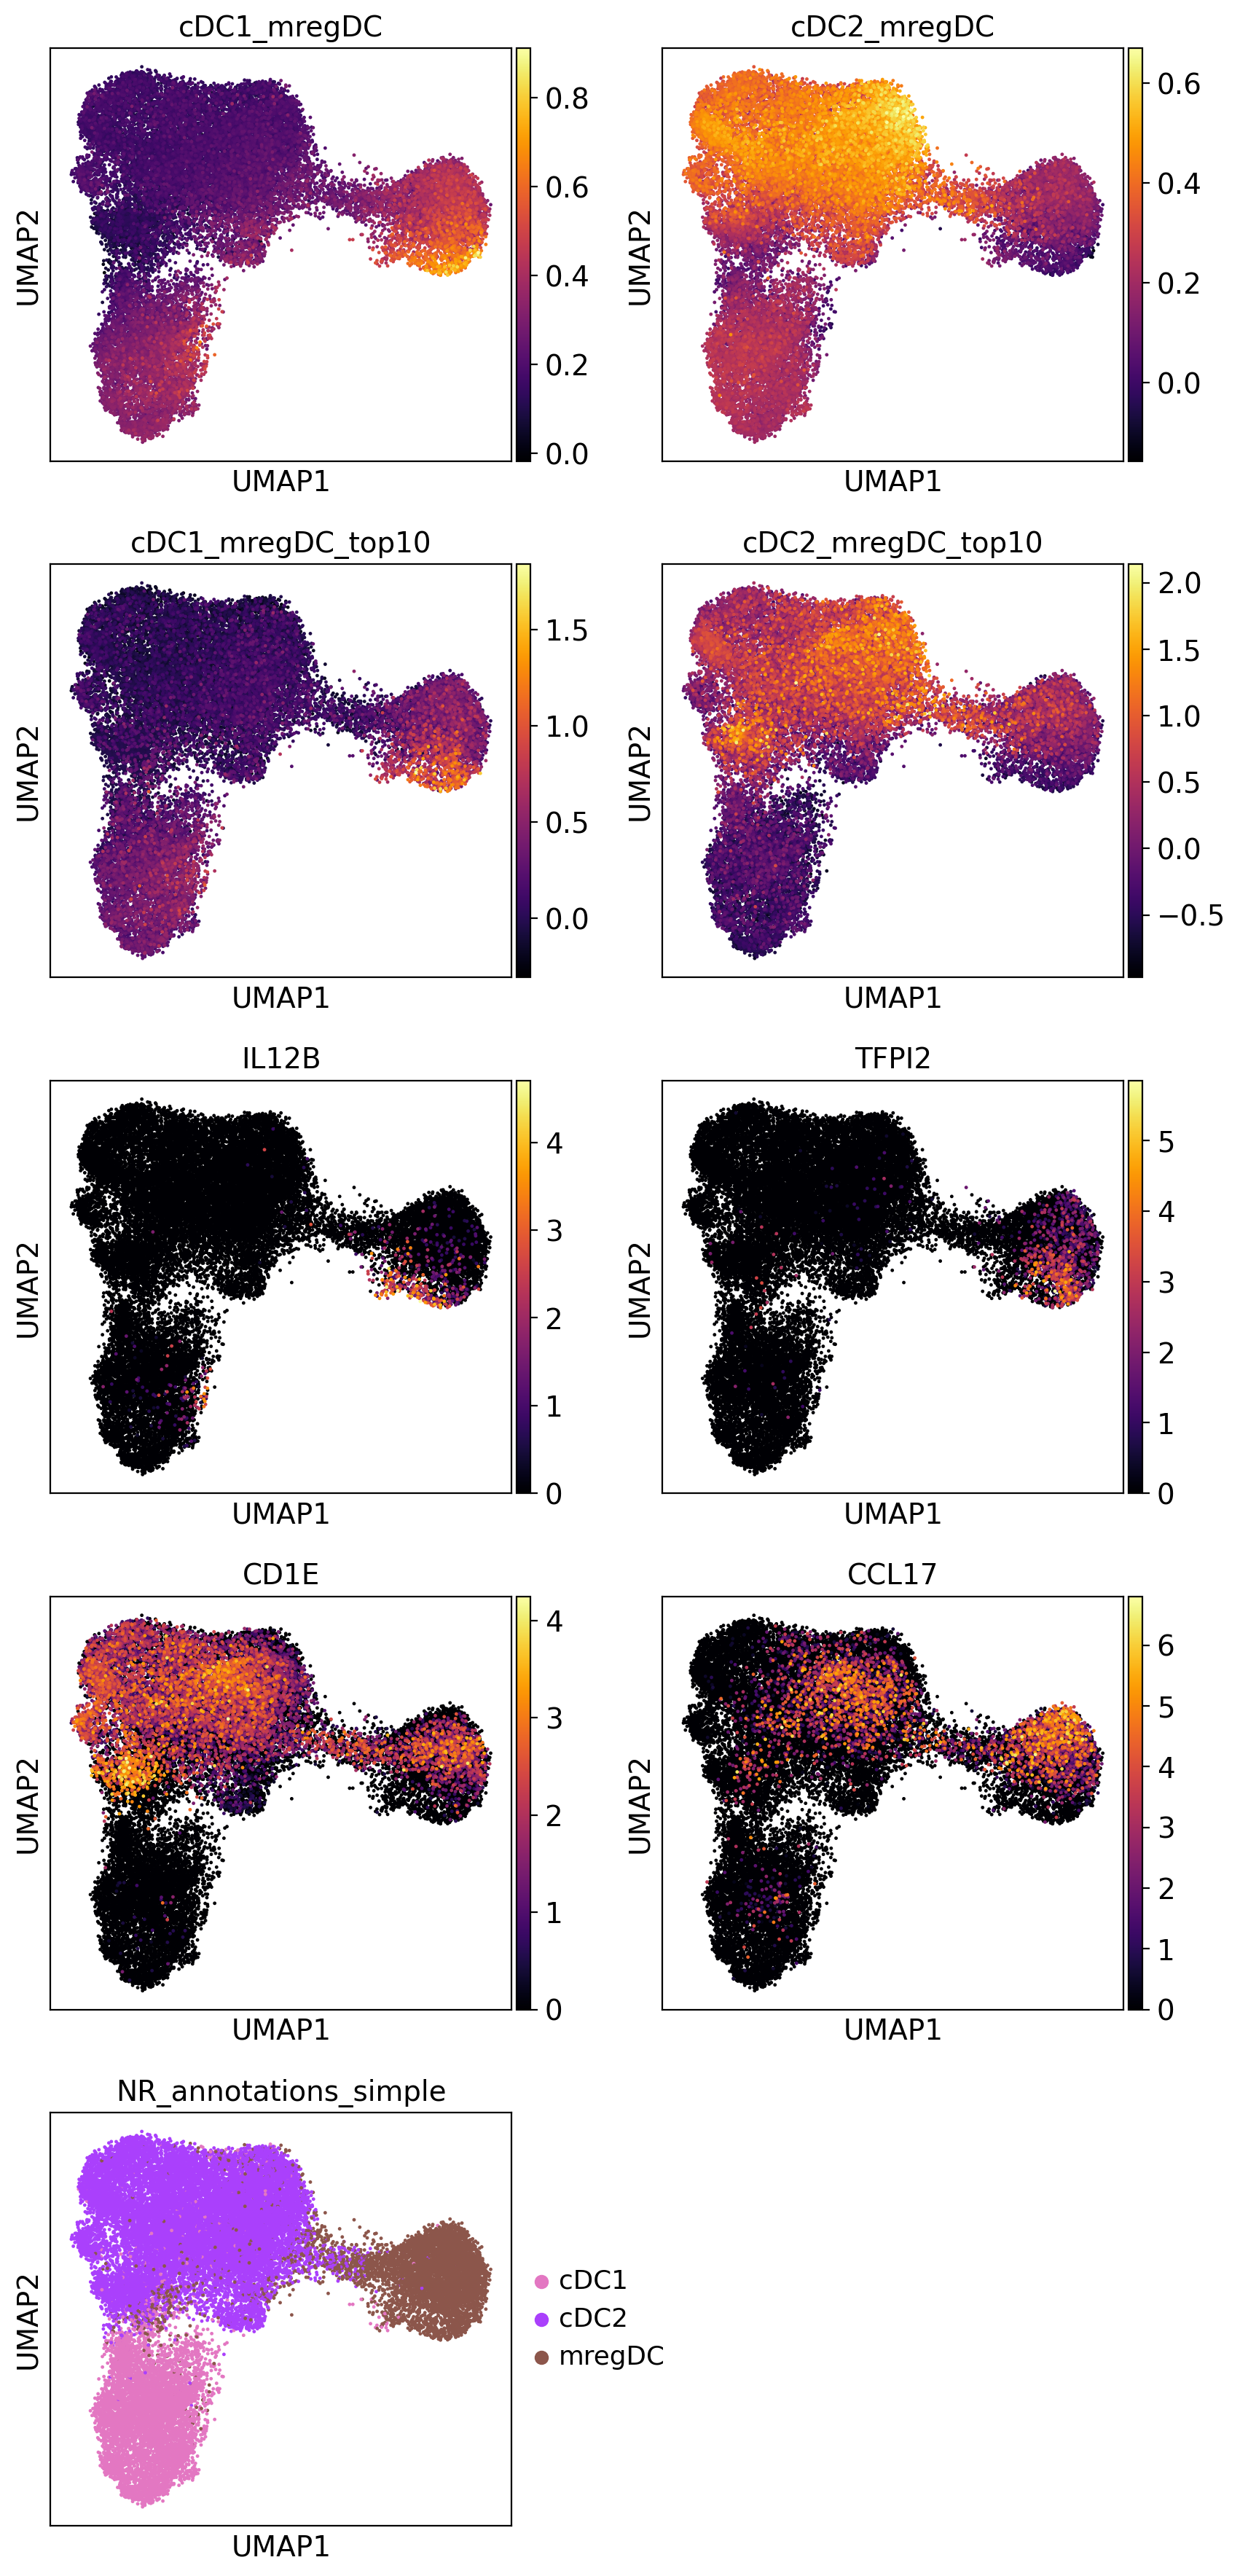

In [25]:
#plotting 
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data, color=colour_vars, ncols=2, size=12, cmap='inferno')

# Consider sub-clustering mregDC using bbknn:

In [26]:
#read in raw data
data_labels = sc.read_h5ad('NRclean_clustered2_DC.h5ad')
data_clean_prehvg = sc.read_h5ad('NR_cleandata.h5ad')

: 

: 

: 

In [ ]:
data_labels

In [ ]:
data_clean_prehvg

In [ ]:
#subset data_clean_prehvg to only the cells in data_labels based on barcode

# Get the list of barcodes (cell names) in data_labels
barcodes_to_keep = data_labels.obs.index

# subset data_clean_prehvg to just those in data_labels
data_clean_prehvg2 = data_clean_prehvg[data_clean_prehvg.obs.index.isin(barcodes_to_keep), :]

data_clean_prehvg2

In [ ]:
# transfer metadata from final atlas (data_labels) to clean data pre-hvg (want pre-hvg data so I can re-do hvg calculation on just DC2)

#define columns to transfer
meta_columns = ['Technology','NR_annotations_simple','sample_type_major2','cancer_with_H','cancer_broadest','patient_treatment']

# Subset the metadata in data_labels to match data_clean_prehvg2's barcodes
metadata_to_transfer = data_labels.obs.loc[data_clean_prehvg2.obs.index, meta_columns]

# Add these columns to data_clean_prehvg2's obs
for col in meta_columns:
    data_clean_prehvg2.obs[col] = metadata_to_transfer[col]

# Verify that the metadata was transferred
data_clean_prehvg2.obs.tail()

In [ ]:
data_labels.obs["NR_annotations_simple"].value_counts()

In [ ]:
# check
data_clean_prehvg2.obs["NR_annotations_simple"].value_counts()

In [ ]:
# subset to just cDC2
data_DC2 = data_clean_prehvg2[data_clean_prehvg2.obs["NR_annotations_simple"] == "cDC2"]